# code_005 · Turn scores into actions and follow their consequences

**Book:** Chapter 1, section 1.4. **Purpose:** executable concept experiments, not a complete estimator hyperparameter course. All data and helper definitions are inside this notebook. Synthetic values are invented for teaching and provide no engineering validation.

Use the repository [quickstart](../README.md) and pinned environment. Restart the kernel and run all cells in order. Verified target: CPython 3.14.3 and scikit-learn 1.9.0, CPU only; no files, downloads, API keys or project imports are needed during execution. Allow a minute for execution plus time to reason through the prompts. Actual time, environment and checks are recorded at the end and in the [Chapter 1 execution report](../CHAPTER_01_EXECUTION.md).

Read each prediction prompt before running its experiment. Controls are identified as task, data-generation, model or decision controls; they are not interchangeable. The [stable directory](../CODE_EXAMPLES.md#code_005) links this example to the manuscript.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=101
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
assert sklearn.__version__=='1.9.0','Use the verified pinned environment.'
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':100,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="static-decision"></a>
## A probability is not an inspection decision

The four supplied probabilities are assumed inputs, not calibrated predictions learned in this notebook. All costs are arbitrary loss units. If an inspection costs C, a finding would otherwise cost L, and inspection averts fraction r of that loss, its expected reduction is p*r*L - C. This assumes the probability and causal prevention fraction are applicable. The code cannot establish either. We compare risk-only and benefit-based choices with capacity two.

**Predict:** will the two largest probabilities produce the greatest expected benefit when consequences differ? Change a consequence or capacity as a decision control; it is not a model hyperparameter. Negative expected benefits should not be selected merely to fill spare capacity.


,member,p,loss_if_finding,inspection_cost,benefit
0,A,0.40,10.0,2.0,0.4
1,B,0.20,100.0,3.0,9.0
2,C,0.10,60.0,2.0,1.6
3,D,0.05,10.0,1.0,-0.7


Chosen by risk: ['A', 'B'] | by expected benefit: ['B', 'C']
Assumption-dependent expected costs: {'none': 30.5, 'risk_only': 21.1, 'expected_benefit': 19.9}


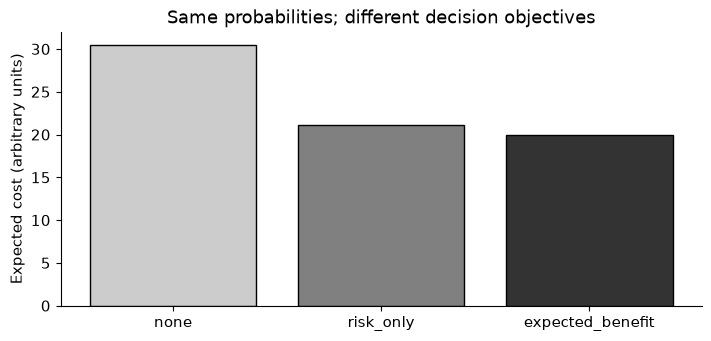

In [2]:
items=pd.DataFrame({'member':['A','B','C','D'],'p':[.4,.2,.1,.05],
 'loss_if_finding':[10.,100.,60.,10.],'inspection_cost':[2.,3.,2.,1.]})
r=.6;capacity=2
items['benefit']=items.p*r*items.loss_if_finding-items.inspection_cost
risk_ids=items.nlargest(capacity,'p').index
benefit_ids=items[items.benefit>0].nlargest(capacity,'benefit').index
assert set(risk_ids)!=set(benefit_ids)
def expected_cost(chosen):
 selected=items.index.isin(chosen)
 return float(np.sum(items.p*items.loss_if_finding*(1-r*selected)+items.inspection_cost*selected))
policies={'none':[],'risk_only':risk_ids,'expected_benefit':benefit_ids}
static={name:expected_cost(ids) for name,ids in policies.items()}
display(items);print('Chosen by risk:',items.loc[risk_ids,'member'].tolist(),'| by expected benefit:',items.loc[benefit_ids,'member'].tolist())
print('Assumption-dependent expected costs:',static)
fig,ax=plt.subplots(figsize=(7,3.3));ax.bar(static.keys(),static.values(),color=['.8','.5','.2'],edgecolor='black')
ax.set(ylabel='Expected cost (arbitrary units)',title='Same probabilities; different decision objectives');plt.show()
RESULTS['static_expected_costs']=static


<a id="sequential"></a>
## A battery action changes the next state

We use six one-hour slots, demand 1 kWh per slot, a 2 kWh battery, initial and required terminal charge 1 kWh, a 1 kWh charge/discharge limit per slot, perfect efficiency, no export and no degradation. Action a is positive for charging and negative for discharging. Next charge is s+a; grid energy is demand+a. Prices are known published tariff values in cost units/kWh, available equally to all policies. They are not forecast with hindsight.

We compare idle, a declared myopic price rule, and exhaustive finite-horizon planning over 3^6 action strings. The planner is an educational planning baseline, not a trained RL agent. Equal terminal charge prevents a policy from appearing cheaper just by leaving the store empty. **Predict:** why can spending extra now reduce total future cost? What happens if a rule discharges before a later expensive slot?


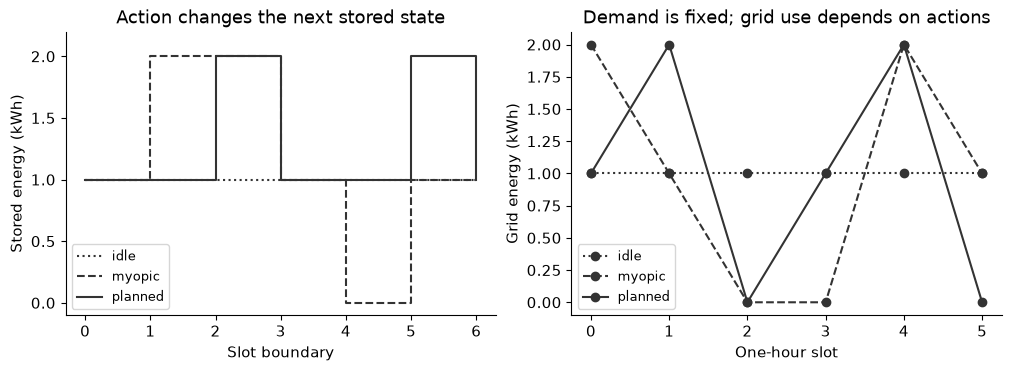

,policy,cost,actions,terminal_kWh
0,idle,19.0,"[0, 0, 0, 0, 0, 0]",1
1,myopic,11.0,"[1, 0, -1, -1, 1, 0]",1
2,planned,10.0,"[0, 1, -1, 0, 1, -1]",1


In [3]:
from itertools import product
prices=np.array([1.,1.,5.,5.,1.,6.]);demand=np.ones(6)
initial=1;cap=2
# Actions measured in kWh over each one-hour slot.
def rollout(actions):
 state=initial;states=[state];grid=[]
 for d,a in zip(demand,actions):
  if abs(a)>1 or not 0<=state+a<=cap or d+a<0:return None
  state+=a;states.append(state);grid.append(d+a)
 if state!=initial:return None
 return {'cost':float(prices@grid),'state':states,'grid':grid,'actions':list(actions)}
idle=rollout([0]*6)
state=initial;myopic_actions=[]
for t,price in enumerate(prices):
 a=min(1,cap-state) if price<=1 else -min(1,state)
 if t==len(prices)-1:a=initial-state
 myopic_actions.append(a);state+=a
myopic=rollout(myopic_actions);assert myopic is not None
feasible=[r for actions in product([-1,0,1],repeat=6) if (r:=rollout(actions)) is not None]
planned=min(feasible,key=lambda r:(r['cost'],tuple(r['actions'])))
assert all(r['state'][0]==r['state'][-1]==initial for r in [idle,myopic,planned])
assert planned['cost']<=min(idle['cost'],myopic['cost'])
fig,ax=plt.subplots(1,2,figsize=(10,3.6))
for name,r,style in [('idle',idle,':'),('myopic',myopic,'--'),('planned',planned,'-')]:
 ax[0].step(range(7),r['state'],where='post',ls=style,label=name,color='.2')
 ax[1].plot(range(6),r['grid'],ls=style,marker='o',label=name,color='.2')
ax[0].set(xlabel='Slot boundary',ylabel='Stored energy (kWh)',title='Action changes the next stored state',ylim=(-.1,2.2))
ax[1].set(xlabel='One-hour slot',ylabel='Grid energy (kWh)',title='Demand is fixed; grid use depends on actions')
for a in ax:a.legend(fontsize=9)
plt.show()
display(pd.DataFrame([{'policy':n,'cost':r['cost'],'actions':r['actions'],'terminal_kWh':r['state'][-1]} for n,r in [('idle',idle),('myopic',myopic),('planned',planned)]]))
RESULTS['sequential_costs']={n:r['cost'] for n,r in [('idle',idle),('myopic',myopic),('planned',planned)]}
RESULTS['planned_actions']=planned['actions'];RESULTS['feasible_plans']=len(feasible)


## Exercises and causal limits

1. Set all member consequences equal. Under which additional equal-cost assumptions does descending probability become a suitable inspection priority?
2. Replace r=0.6 with 0.2 and 0.9 as declared sensitivity cases. Explain why observational inspection correlations cannot identify r by themselves.
3. Inspect a member only if selected, then record outcomes only for inspected members. Explain why uninspected outcomes are unknown, not negative labels.
4. Raise the required terminal storage or introduce efficiency below one. Rewrite the transition and grid equations before modifying the code.
5. Replace known tariffs with uncertain future prices. Identify the extra information the current planner assumes and design an honest comparison.

**Optional hint:** a policy maps information and state to an action. A forecast is one possible input. The transition defines how an action changes the next state. Rewards are task choices, and an apparent benefit is conditional on the transition and consequence assumptions. No RL algorithm or causal effect is learned here.


## Interpretation, limits and next steps

The printed tables and figures are observations from this executed synthetic experiment. Describe the mechanism they demonstrate before comparing individual numbers. Fixed seeds make the teaching run reproducible; they do not establish performance in a new population. No deployment or physical validity guarantee follows from passing these checks. For model-specific controls, use the official documentation and the later model chapters; [code_001](../CODE_EXAMPLES.md#code_001) is a full decision-tree parameter laboratory.

**Troubleshooting:** a version assertion means the selected kernel differs from the pinned environment. Restart and run all cells rather than borrowing state from a different notebook. Missing or repeated timestamps require an explicit observation policy, not a silent row reorder. When adapting an experiment, record its new assumptions, selection rule and untouched assessment evidence. Initial package installation may use the internet; these cells do not.


In [4]:
EXECUTION_SUMMARY={'example_id':'code_005','versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU',
 'seed':SEED,'concepts_demonstrated':['probabilities versus actions', 'capacity and expected cost', 'causal prevention assumptions', 'policy and state', 'sequential transitions', 'terminal fairness', 'planning baseline versus RL'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:',json.dumps(EXECUTION_SUMMARY,sort_keys=True))


EXECUTION_SUMMARY_JSON: {"concepts_demonstrated": ["probabilities versus actions", "capacity and expected cost", "causal prevention assumptions", "policy and state", "sequential transitions", "terminal fairness", "planning baseline versus RL"], "elapsed_seconds": 0.168, "example_id": "code_005", "hardware": "Darwin arm64 CPU", "results": {"feasible_plans": 99, "planned_actions": [0, 1, -1, 0, 1, -1], "sequential_costs": {"idle": 19.0, "myopic": 11.0, "planned": 10.0}, "static_expected_costs": {"expected_benefit": 19.9, "none": 30.5, "risk_only": 21.1}}, "seed": 101, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
